In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, log_loss, confusion_matrix,
    classification_report
)

# Load dataset
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Classes:", list(dataset.target_names))
print("\nClass distribution:")
print(y.map(dict(enumerate(dataset.target_names))).value_counts())


Dataset loaded successfully!
Number of samples: 569
Number of features: 30
Classes: [np.str_('malignant'), np.str_('benign')]

Class distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training and testing split completed successfully.")


Training samples: 455
Testing samples: 114
Training and testing split completed successfully.


In [4]:

models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Gaussian Naive Bayes": GaussianNB()
}

print("Four classification models created:")
for name in models:
    print("-", name)


Four classification models created:
- SVM
- Decision Tree
- KNN
- Gaussian Naive Bayes


In [5]:

results = []
predictions = {}

for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)

    # Predict test labels and probabilities
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    loss = log_loss(y_test, y_prob, labels=[0, 1])

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Log Loss": loss
    })

    predictions[name] = y_pred

    print("\n" + "=" * 45)
    print("MODEL:", name)
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(f"Log Loss : {loss:.4f}")
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=dataset.target_names,
        zero_division=0
    ))



MODEL: SVM
Accuracy : 0.9825
Precision: 0.9812
Recall   : 0.9812
F1-score : 0.9812
Log Loss : 0.0860

Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


MODEL: Decision Tree
Accuracy : 0.9123
Precision: 0.9019
Recall   : 0.9157
F1-score : 0.9075
Log Loss : 3.1617

Confusion Matrix:
[[39  3]
 [ 7 65]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114


MODEL: 

In [6]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

print("COMPARATIVE ANALYSIS OF CLASSIFICATION MODELS")
display(results_df.round(4))


COMPARATIVE ANALYSIS OF CLASSIFICATION MODELS


,Model,Accuracy,Precision,Recall,F1-score,Log Loss
0,SVM,0.9825,0.9812,0.9812,0.9812,0.0860
1,KNN,0.9561,0.9551,0.9504,0.9526,0.4073
2,Gaussian Naive Bayes,0.9386,0.9360,0.9315,0.9337,0.3713
3,Decision Tree,0.9123,0.9019,0.9157,0.9075,3.1617


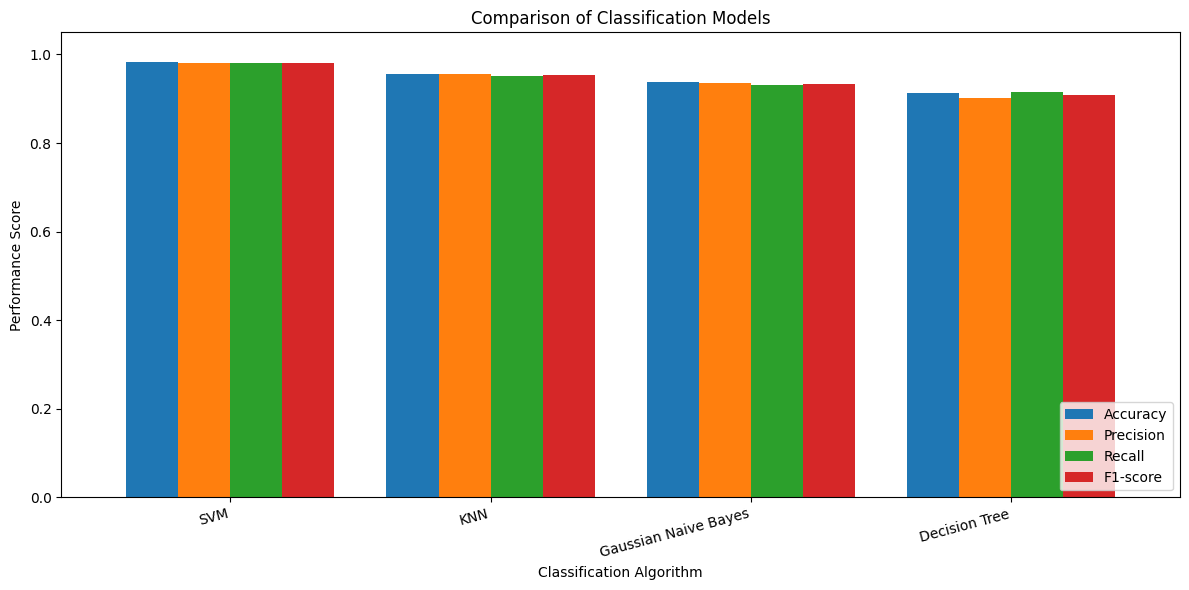

In [7]:

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

plot_df = results_df.set_index("Model")[metrics]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    width=0.8
)

ax.set_title("Comparison of Classification Models")
ax.set_xlabel("Classification Algorithm")
ax.set_ylabel("Performance Score")
ax.legend(loc="lower right")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    "classification_model_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


In [8]:

best_model = results_df.loc[results_df["F1-score"].idxmax()]

print("BEST MODEL BASED ON MACRO F1-SCORE")
print("Model:", best_model["Model"])
print(f"Accuracy: {best_model['Accuracy']:.4f}")
print(f"Precision: {best_model['Precision']:.4f}")
print(f"Recall: {best_model['Recall']:.4f}")
print(f"F1-score: {best_model['F1-score']:.4f}")
print(f"Log Loss: {best_model['Log Loss']:.4f}")

print("\nFinal observation:")
print(
    "The best model is selected using macro F1-score. "
    "Model suitability also depends on the application "
    "and the cost of classification errors."
)


BEST MODEL BASED ON MACRO F1-SCORE
Model: SVM
Accuracy: 0.9825
Precision: 0.9812
Recall: 0.9812
F1-score: 0.9812
Log Loss: 0.0860

Final observation:
The best model is selected using macro F1-score. Model suitability also depends on the application and the cost of classification errors.


In [9]:

from google.colab import files

results_df.to_csv(
    "classification_model_results.csv",
    index=False
)

print("Results CSV created successfully.")
files.download("classification_model_results.csv")


Results CSV created successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:

files.download("classification_model_comparison.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>